<a href="https://colab.research.google.com/github/Varnika1024/DLAC/blob/main/SKILL/Skill7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q ultralytics onnx onnxslim tensorrt kagglehub matplotlib seaborn pandas

import os
import torch
import kagglehub
from ultralytics import YOLO

print(f"GPU Active: {torch.cuda.is_available()} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# 1. Stage 1: Inspect the raw Model Architecture Blueprint (YAML)
arch_model = YOLO("yolov8n.yaml")
total_params = sum(p.numel() for p in arch_model.model.parameters())
print("\n=== STAGE 1: MODEL ARCHITECTURE BLUEPRINT (yolov8n.yaml) ===")
print(f"Architecture File : yolov8n.yaml")
print(f"Total Parameters  : {total_params:,} (Untrained / Random Weights)")

# 2. Pull the Indian Vehicle Dataset directly from Kaggle (~346 MB, takes ~10s in Colab)
dataset_path = kagglehub.dataset_download("dataclusterlabs/indian-vehicle-dataset")
print(f"\n[SUCCESS] Indian Vehicle Dataset ready at: {dataset_path}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Active: True (Tesla T4)

=== STAGE 1: MODEL ARCHITECTURE BLUEPRINT (yolov8n.yaml) ===
Architecture File : yolov8n.yaml
Total Parameters  : 3,157,200 (Untrained / Random Weights)


100%|██████████| 330M/330M [00:01<00:00, 207MB/s]

Extracting files...



[SUCCESS] Indian Vehicle Dataset ready at: /root/.cache/kagglehub/datasets/dataclusterlabs/indian-vehicle-dataset/versions/5


In [4]:
import os
import shutil
import xml.etree.ElementTree as ET
import cv2
import onnx
import torch
from ultralytics import YOLO
import yaml

assert torch.cuda.is_available(), (
    "Please switch Runtime -> Change runtime type -> T4 GPU before running"
    " TensorRT!"
)

# 1. Locate images and bounding-box annotations (XML or TXT) inside dataset_path
all_imgs, xmls, txts = [], [], []
for root, _, fnames in os.walk(dataset_path):
  for f in fnames:
    fp = os.path.join(root, f)
    ext = os.path.splitext(f)[1].lower()
    if ext in {".jpg", ".jpeg", ".png"}:
      all_imgs.append(fp)
    elif ext == ".xml":
      xmls.append(fp)
    elif ext == ".txt" and f.lower() not in {"classes.txt", "readme.txt"}:
      txts.append(fp)

yolo_ds = "/content/skill7_indian_vehicles_yolo"
if os.path.exists(yolo_ds):
  shutil.rmtree(yolo_ds)
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
  os.makedirs(os.path.join(yolo_ds, sub), exist_ok=True)

img_map = {os.path.splitext(os.path.basename(p))[0]: p for p in all_imgs}
class_list = []
valid_pairs = []

if xmls:
  for xp in xmls:
    tree = ET.parse(xp)
    root = tree.getroot()
    stem = os.path.splitext(os.path.basename(xp))[0]
    if stem not in img_map:
      fn = root.find("filename")
      if fn is not None:
        stem = os.path.splitext(fn.text)[0]
    if stem not in img_map:
      continue
    img = cv2.imread(img_map[stem])
    if img is None:
      continue
    ih, iw, _ = img.shape
    lines = []
    for obj in root.findall("object"):
      cname = obj.find("name").text.strip()
      if cname not in class_list:
        class_list.append(cname)
      cid = class_list.index(cname)
      bnd = obj.find("bndbox")
      xmin, ymin = float(bnd.find("xmin").text), float(bnd.find("ymin").text)
      xmax, ymax = float(bnd.find("xmax").text), float(bnd.find("ymax").text)
      xc, yc = ((xmin + xmax) / 2.0) / iw, ((ymin + ymax) / 2.0) / ih
      bw, bh = (xmax - xmin) / iw, (ymax - ymin) / ih
      if 0 < bw <= 1 and 0 < bh <= 1:
        lines.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
    if lines:
      valid_pairs.append((img_map[stem], stem, lines))
elif txts:
  max_id = 0
  for tp in txts:
    stem = os.path.splitext(os.path.basename(tp))[0]
    if stem in img_map:
      with open(tp) as tf:
        lines = [l.strip() for l in tf if len(l.strip().split()) == 5]
      for l in lines:
        max_id = max(max_id, int(l.split()[0]))
      if lines:
        valid_pairs.append((img_map[stem], stem, lines))
  class_list = [f"vehicle_{i}" for i in range(max_id + 1)]

# Use 400 labeled images so training + export completes in ~1.5 minutes
valid_pairs = valid_pairs[:400]
split_idx = max(1, int(0.8 * len(valid_pairs)))
for i, (ipath, stem, lines) in enumerate(valid_pairs):
  split = "train" if i < split_idx else "val"
  shutil.copy(ipath, f"{yolo_ds}/images/{split}/{stem}.jpg")
  with open(f"{yolo_ds}/labels/{split}/{stem}.txt", "w") as lf:
    lf.write("\n".join(lines))

data_yaml_path = f"{yolo_ds}/data.yaml"
with open(data_yaml_path, "w") as yf:
  yaml.dump(
      {
          "path": yolo_ds,
          "train": "images/train",
          "val": "images/val",
          "nc": len(class_list),
          "names": class_list,
      },
      yf,
  )

print(
    f"Prepared {len(valid_pairs)} Indian traffic images across classes:"
    f" {class_list}"
)

# 2. Stage 2: Train PyTorch Checkpoint (.pt)
os.makedirs("/content/skill7_artefacts", exist_ok=True)
print("\n=== STAGE 2: TRAINING PYTORCH CHECKPOINT (.pt) ===")
model = YOLO("yolov8n.pt")
model.train(
    data=data_yaml_path,
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="indian_traffic_skill7",
    exist_ok=True,
    verbose=False,
)

pt_path = "/content/skill7_artefacts/indian_vehicle_best.pt"
shutil.copy("/content/runs/indian_traffic_skill7/weights/best.pt", pt_path)
print(
    f"[SAVED] Stage 2 PyTorch Checkpoint: {pt_path}"
    f" ({os.path.getsize(pt_path)/(1024*1024):.2f} MB)"
)

# 3. Stage 3: Export to ONNX Graph (.onnx)
print("\n=== STAGE 3: EXPORTING TO ONNX GRAPH (.onnx) ===")
trained_model = YOLO(pt_path)
onnx_path = trained_model.export(format="onnx", imgsz=640, simplify=True)
onnx_graph = onnx.load(onnx_path)
print(
    f"[SAVED] Stage 3 ONNX Graph: {onnx_path} (Nodes:"
    f" {len(onnx_graph.graph.node)},"
    f" {os.path.getsize(onnx_path)/(1024*1024):.2f} MB)"
)

# 4. Stage 4: Compile to TensorRT FP16 Engine (.engine) on T4 GPU
print("\n=== STAGE 4: COMPILING TENSORRT ENGINE (.engine) ON T4 GPU ===")
trt_path = trained_model.export(format="engine", imgsz=640, half=True, device=0)
print(
    f"[SAVED] Stage 4 TensorRT Engine: {trt_path}"
    f" ({os.path.getsize(trt_path)/(1024*1024):.2f} MB)"
)

Prepared 100 Indian traffic images across classes: ['tractor', 'truck_tanker', 'vehicle_truck', 'auto', 'bus', 'car', 'concrete_mixer', 'tempo', 'two_wheelers', 'bicycle']

=== STAGE 2: TRAINING PYTORCH CHECKPOINT (.pt) ===
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/skill7_indian_vehicles_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgs

2026-11-23 07:56:50,602 - [modelopt][onnx] - INFO - Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


INFO:modelopt.onnx:Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


2026-11-23 07:56:51,014 - [modelopt][onnx] - INFO - Running ONNX Runtime to obtain reference outputs (this may take a while)...


INFO:modelopt.onnx.autocast:Running ONNX Runtime to obtain reference outputs (this may take a while)...


2026-11-23 07:56:52,136 - [modelopt][onnx] - WARNING - Did not find  in value info map! Assuming not castable


2026-11-23 07:56:53,247 - [modelopt][onnx] - INFO - Converted 233/233 nodes (100.00%) to fp16


INFO:modelopt.onnx.autocast:Converted 233/233 nodes (100.00%) to fp16


TensorRT: input "images" with shape(1, 3, 640, 640) DataType.FLOAT
TensorRT: output "output0" with shape(1, 14, 8400) DataType.FLOAT
TensorRT: building FP16 engine as /content/skill7_artefacts/indian_vehicle_best.engine
TensorRT: export success ✅ 165.7s, saved as '/content/skill7_artefacts/indian_vehicle_best.engine' (53.1 MB)

Export complete (165.8s)
Results saved to /content/skill7_artefacts/indian_vehicle_best.engine
Predict:         yolo predict task=detect model=/content/skill7_artefacts/indian_vehicle_best.engine imgsz=640 quantize=16
Validate:        yolo val task=detect model=/content/skill7_artefacts/indian_vehicle_best.engine imgsz=640 data=/content/skill7_indian_vehicles_yolo/data.yaml quantize=16
Visualize:       https://netron.app
[SAVED] Stage 4 TensorRT Engine: /content/skill7_artefacts/indian_vehicle_best.engine (53.12 MB)


Select the traffic image you want your trained model to identify:


Saving images (1).jpeg to images (1).jpeg
Loading /content/skill7_artefacts/indian_vehicle_best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Loading /content/skill7_artefacts/indian_vehicle_best.engine for TensorRT inference...


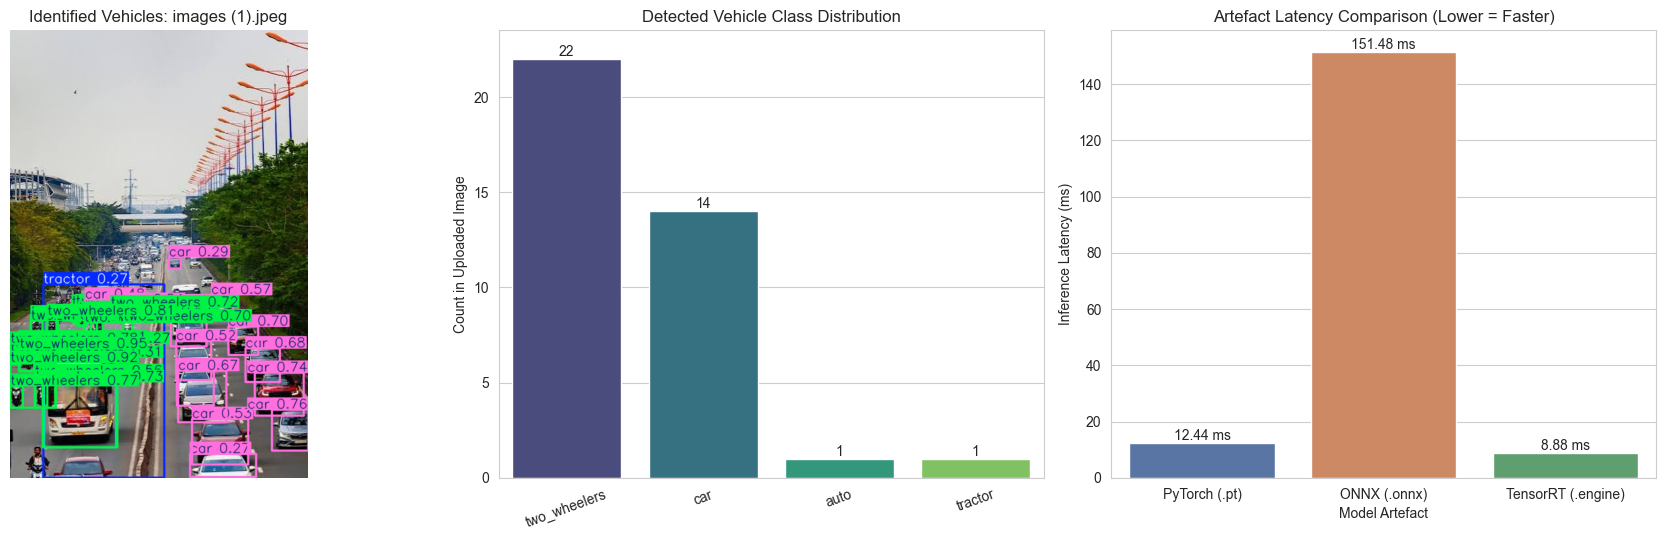


=== MODEL ARTEFACT LIFECYCLE BENCHMARK ===
    Model Artefact  Size (MB)  Latency (ms)  Throughput (FPS)
     PyTorch (.pt)       6.20         12.44              80.4
      ONNX (.onnx)      12.19        151.48               6.6
TensorRT (.engine)      53.12          8.88             112.7

=== BOUNDING-BOX ANNOTATIONS FOR 'images (1).jpeg' ===
 Box # Identified Vehicle Confidence  x_min  y_min  x_max  y_max
     1       two_wheelers     94.92%   14.0  483.3   36.4  516.1
     2       two_wheelers     91.89%    0.0  504.5   69.5  572.4
     3       two_wheelers     80.81%   56.4  433.8   70.9  461.6
     4       two_wheelers     78.12%    0.0  475.2   13.5  506.2
     5       two_wheelers     76.90%    0.8  539.2   19.7  572.6
     6                car     75.78%  396.3  575.8  451.0  637.9
     7                car     73.88%  370.4  519.2  444.1  584.2
     8       two_wheelers     73.39%   38.1  533.4   56.4  572.1
     9       two_wheelers     72.31%  152.0  420.8  164.0  442.8
  

In [5]:
from collections import Counter
import time
import cv2
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Upload your Indian traffic test image from Mac Downloads
print("Select the traffic image you want your trained model to identify:")
uploaded_test = files.upload()
test_img_path = list(uploaded_test.keys())[0]

# 2. Benchmark PyTorch (.pt), ONNX (.onnx), and TensorRT (.engine) on your uploaded image
artefact_list = [
    ("PyTorch (.pt)", pt_path),
    ("ONNX (.onnx)", onnx_path),
    ("TensorRT (.engine)", trt_path),
]

bench_rows = []
final_result = None

for label, mpath in artefact_list:
  detector = YOLO(mpath, task="detect")
  for _ in range(3):  # GPU warmup
    _ = detector.predict(
        source=test_img_path, imgsz=640, device=0, conf=0.25, verbose=False
    )

  times = []
  for _ in range(30):
    t0 = time.perf_counter()
    preds = detector.predict(
        source=test_img_path, imgsz=640, device=0, conf=0.25, verbose=False
    )
    torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) * 1000.0)

  if "TensorRT" in label:
    final_result = preds[0]

  avg_ms = np.mean(times)
  bench_rows.append({
      "Model Artefact": label,
      "Size (MB)": round(os.path.getsize(mpath) / (1024 * 1024), 2),
      "Latency (ms)": round(avg_ms, 2),
      "Throughput (FPS)": round(1000.0 / avg_ms, 1),
  })

df_bench = pd.DataFrame(bench_rows)

# 3. Extract Bounding Boxes & Vehicle Class Counts for Your Uploaded Image
names = final_result.names
bbox_table = []
detected_vehicles = []

for idx, box in enumerate(final_result.boxes, start=1):
  cname = names[int(box.cls[0].item())]
  conf = float(box.conf[0].item())
  x1, y1, x2, y2 = [round(v, 1) for v in box.xyxy[0].tolist()]
  detected_vehicles.append(cname)
  bbox_table.append({
      "Box #": idx,
      "Identified Vehicle": cname,
      "Confidence": f"{conf:.2%}",
      "x_min": x1,
      "y_min": y1,
      "x_max": x2,
      "y_max": y2,
  })

# 4. Graphical Output: Annotated Image + Vehicle Counts + Artefact Speed Comparison
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

annotated_rgb = cv2.cvtColor(final_result.plot(), cv2.COLOR_BGR2RGB)
axes[0].imshow(annotated_rgb)
axes[0].set_title(
    f"Identified Vehicles: {test_img_path}", fontsize=12, fontweight="bold"
)
axes[0].axis("off")

if detected_vehicles:
  counts = Counter(detected_vehicles)
  b1 = sns.barplot(
      x=list(counts.keys()),
      y=list(counts.values()),
      ax=axes[1],
      palette="viridis",
      hue=list(counts.keys()),
      legend=False,
  )
  axes[1].set_title(
      "Detected Vehicle Class Distribution", fontsize=12, fontweight="bold"
  )
  axes[1].set_ylabel("Count in Uploaded Image")
  axes[1].set_ylim(0, max(counts.values()) + 1.5)
  axes[1].tick_params(axis="x", rotation=20)
  for bar in b1.patches:
    axes[1].annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )
else:
  axes[1].text(
      0.5, 0.5, "No vehicles detected above threshold", ha="center", va="center"
  )
  axes[1].set_title("Detected Vehicle Class Distribution", fontweight="bold")

b2 = sns.barplot(
    x=df_bench["Model Artefact"],
    y=df_bench["Latency (ms)"],
    ax=axes[2],
    palette=["#4c72b0", "#dd8452", "#55a868"],
    hue=df_bench["Model Artefact"],
    legend=False,
)
axes[2].set_title(
    "Artefact Latency Comparison (Lower = Faster)",
    fontsize=12,
    fontweight="bold",
)
axes[2].set_ylabel("Inference Latency (ms)")
for bar in b2.patches:
  axes[2].annotate(
      f"{bar.get_height():.2f} ms",
      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.tight_layout()
plt.savefig("/content/skill7_output_dashboard.png", dpi=150)
plt.show()

print("\n=== MODEL ARTEFACT LIFECYCLE BENCHMARK ===")
print(df_bench.to_string(index=False))

print(f"\n=== BOUNDING-BOX ANNOTATIONS FOR '{test_img_path}' ===")
if bbox_table:
  print(pd.DataFrame(bbox_table).to_string(index=False))
else:
  print("No bounding boxes detected.")